**Netflix_Content_Type_Prediction_System**

**Dataset:** `Dataset.csv`

### **1. Setup**

In [753]:
%pip install numpy pandas scikit-learn matplotlib seaborn imbalanced-learn -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [754]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [755]:
# configuration setup
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="darkgrid")

RANDOM_STATE = 42
TARGET_COL = "type"

### **2. Loading Dataset**

In [756]:
df = pd.read_csv(r"C:\Users\bhara\Desktop\Bharath Hottin\Education\Machine_Learning\ML_internship_Project\Netflix_Content_Type_Predictor_System\Dataset\Dataset.csv")

### **3. Exploratory Data Analysis (EDA)**

In [757]:
df.shape

(8790, 10)

In [758]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


In [759]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='str')

In [760]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [761]:
df.tail()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,6/7/2018,2016,TV-Y7,1 Season,Kids' TV


In [762]:
df.nunique()

show_id         8790
type               2
title           8787
director        4528
country           86
date_added      1713
release_year      74
rating            14
duration         220
listed_in        513
dtype: int64

In [763]:
df.describe()

,release_year
count,8790.000
mean,2014.183
std,8.825
min,1925.000
25%,2013.000
50%,2017.000
75%,2019.000
max,2021.000


In [764]:
# check for missing values
df.isna().sum().sort_values()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [765]:
# check for encoded missing values
for col in df.columns:
    print(df[col].value_counts().head(10))

show_id
s1      1
s3      1
s6      1
s14     1
s8      1
s9      1
s10     1
s939    1
s13     1
s940    1
Name: count, dtype: int64
type
Movie      6126
TV Show    2664
Name: count, dtype: int64
title
9-Feb                               2
15-Aug                              2
22-Jul                              2
Dick Johnson Is Dead                1
Ganglands                           1
Midnight Mass                       1
Confessions of an Invisible Girl    1
Sankofa                             1
The Great British Baking Show       1
The Starling                        1
Name: count, dtype: int64
director
Not Given                 2588
Rajiv Chilaka               20
Raúl Campos, Jan Suter      18
Alastair Fothergill         18
Suhas Kadav                 16
Marcus Raboy                16
Jay Karas                   14
Cathy Garcia-Molina         13
Youssef Chahine             12
Martin Scorsese             12
Name: count, dtype: int64
country
United States     3240
India          

In [766]:
# check for duplicates
for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].str.strip()                                   # remove stray spaces
before = len(df)
df = df.drop_duplicates(subset=df.columns.drop("show_id"))          # same title listed twice
df = df.reset_index(drop=True)
print(f"Rows: {before:,} -> {len(df):,}  ({before - len(df)} duplicates removed)")
df["type"].value_counts()

Rows: 8,790 -> 8,786  (4 duplicates removed)


type
Movie      6123
TV Show    2663
Name: count, dtype: int64

In [767]:
# identify columns with not given
not_given_summary = (
    df.eq("Not Given")
      .sum()
      .to_frame(name="not_count")
      .assign(not_percentage=lambda x: (x["not_count"] / len(df)) * 100)
)

not_given_summary

,not_count,not_percentage
show_id,0,0.000
type,0,0.000
title,0,0.000
director,2587,29.445
country,287,3.267
date_added,0,0.000
release_year,0,0.000
rating,0,0.000
duration,0,0.000
listed_in,0,0.000


In [768]:
# droping id column
df=df.drop(columns=["show_id"])

In [769]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   type          8786 non-null   str  
 1   title         8786 non-null   str  
 2   director      8786 non-null   str  
 3   country       8786 non-null   str  
 4   date_added    8786 non-null   str  
 5   release_year  8786 non-null   int64
 6   rating        8786 non-null   str  
 7   duration      8786 non-null   str  
 8   listed_in     8786 non-null   str  
dtypes: int64(1), str(8)
memory usage: 617.9 KB


In [770]:
df[TARGET_COL].value_counts()

type
Movie      6123
TV Show    2663
Name: count, dtype: int64

In [771]:
df[TARGET_COL].value_counts(normalize=True)

type
Movie     0.697
TV Show   0.303
Name: proportion, dtype: float64

**Data Visualization**

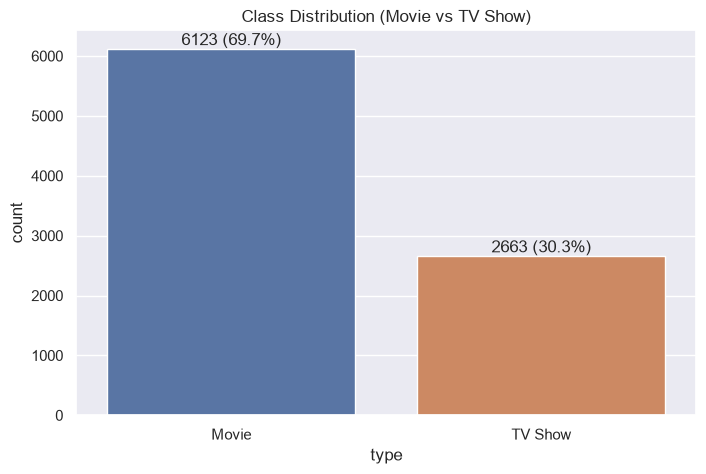

In [772]:
# visualize class imbalance
plt.figure(figsize=(8, 5))
ax = sns.countplot(x=TARGET_COL, data=df, hue="type")
for bars in ax.containers:
    ax.bar_label(bars, fmt=lambda c: f"{c:.0f} ({c / len(df):.1%})")
plt.title("Class Distribution (Movie vs TV Show)")
plt.show()

- The target column i.e **type** column is clearly **imbalanced** 
- The **Movie** alone has **70%** of the data and **TV Show** has only **30%** data

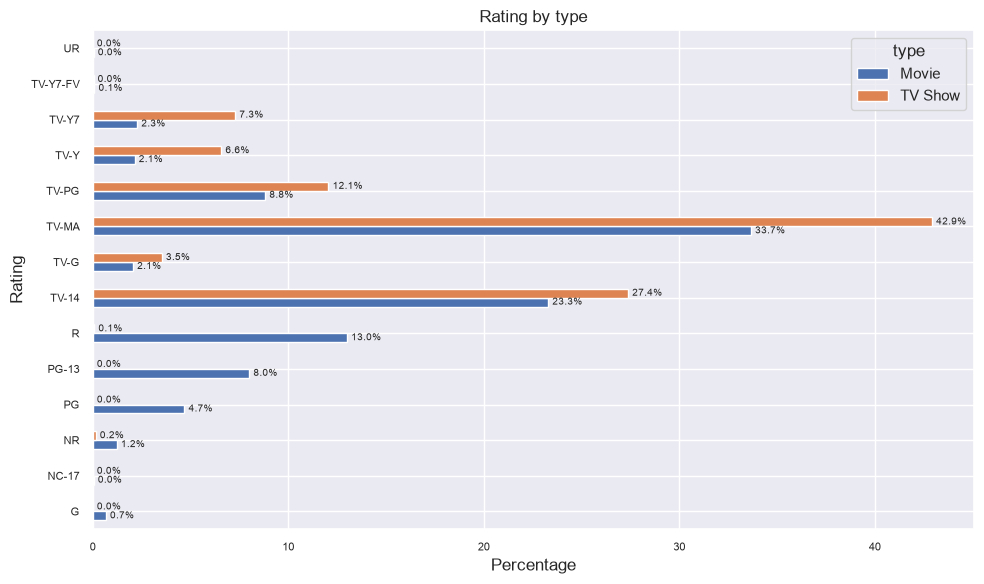

In [773]:
# visualing rating wrt type
graph = pd.crosstab(df["rating"], df["type"], normalize="columns")*100
ax = graph.plot(kind="barh", figsize=(10,6), fontsize=8)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=7)
plt.title("Rating by type") 
plt.xlabel("Percentage")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()   

- **R ,G ,NR ,PG-13** rating occur only on **Movie**
- **TV-14 ,TV-G ,TV-MA ,TV-PG ,TV-Y ,TV-Y7** rating occur on both **Movie** and **TV Show**
- **UR ,TV-Y7-FV ,NC-17** neither occur on **Movie** nor **TV Show**

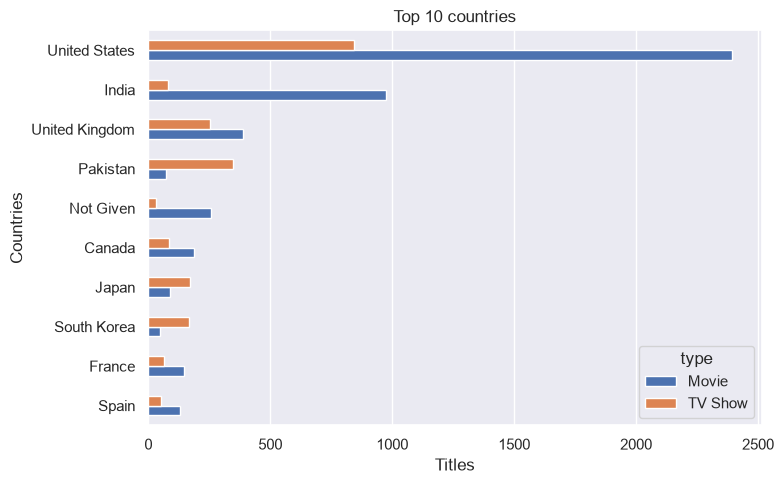

In [774]:
# visualizing the contries wrt type
top = df["country"].fillna("Unknown").value_counts().head(10).index
tab = pd.crosstab(df["country"], df["type"]).loc[top][["Movie", "TV Show"]]
ax = tab.iloc[::-1].plot.barh(figsize=(8,5))
ax.set_title("Top 10 countries") 
ax.set_ylabel("Countries"); 
ax.set_xlabel("Titles")
ax.grid(axis="y", visible=False)
ax.legend(title="type")
plt.tight_layout()
plt.show()

- Pakistan has 83% TV show titles , South Korea with 77% of TV Show and Japan with 66% of TV show titles, The United Kingdom is 39% while India 8% and titles with no country 10% are mostly movies. 

### **4. Data Pre-Processing**

In [775]:
# drop duration column to prevent data leakage 
df = df.drop(columns="duration")

In [776]:
# drop title column as this column diverts the model
df = df.drop(columns="title")

In [777]:
# Encoding Target column Movie -> 0 and TV Show -> 1
df[TARGET_COL] = df[TARGET_COL].map({"Movie": 0, "TV Show" : 1})

In [778]:
print("type (full dataset)")
print(df[TARGET_COL].value_counts())

print("type (full dataset) in percentage")
print(df[TARGET_COL].value_counts(normalize=True))

type (full dataset)
type
0    6123
1    2663
Name: count, dtype: int64
type (full dataset) in percentage
type
0   0.697
1   0.303
Name: proportion, dtype: float64


In [779]:
import re

In [780]:
y = df[TARGET_COL]      

LISTIN_TYPE = {
    "Docuseries": "Documentaries",
    "Kids": "Children & Family",
    "Stand-Up Comedy & Talk": "Stand-Up Comedy",
    "Classic": "Classic & Cult",
    "Cult" : "Classic & Cult"
}

def cleaned_listin(text):
    names = []
    for g in text.split(","):
        g = re.sub(r"\b(TV|Movies|Shows|Series|Features)\b", "", g)
        g = " ".join(g.split())
        g = LISTIN_TYPE.get(g, g)
        if g:
            names.append(g)
    return ",".join(sorted(set(names))) 

New_Listed_in = df["listed_in"].apply(cleaned_listin).str.get_dummies(sep=",").drop(columns="", errors="ignore") 
New_Listed_in.columns = ["listed_" + c for c in New_Listed_in.columns]          


X = pd.DataFrame(index=df.index)
X["release_year"] = df["release_year"]
X["year_added"] = pd.to_datetime(df["date_added"], format="%m/%d/%Y").dt.year
X["has_director"] = (df["director"] != "Not Given").astype(int)

rating = pd.get_dummies(df["rating"], prefix="rating", dtype=int)  # one-hot encoding 

X = pd.concat([X, rating, New_Listed_in], axis=1)
print("Feature table:", X.shape[0], "rows x", X.shape[1], "columns")
print("Missing values:", int(X.isna().sum().sum()))
print("Columns: 3 numbers +", rating.shape[1], "ratings +", New_Listed_in.shape[1], "Lists")

Feature table: 8786 rows x 44 columns
Missing values: 0
Columns: 3 numbers + 14 ratings + 27 Lists


In [781]:
X.head()

,release_year,year_added,has_director,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR,listed_Action & Adventure,listed_Anime,listed_British,listed_Children & Family,listed_Classic & Cult,listed_Comedies,listed_Crime,listed_Documentaries,listed_Dramas,listed_Faith & Spirituality,listed_Horror,listed_Independent,listed_International,listed_Kids',listed_Korean,listed_LGBTQ,listed_Music & Musicals,listed_Mysteries,listed_Reality,listed_Romantic,listed_Sci-Fi & Fantasy,listed_Science & Nature,listed_Spanish-Language,listed_Sports,listed_Stand-Up Comedy,listed_Teen,listed_Thrillers
0,2020,2021,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2021,2021,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2021,2021,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,2021,2021,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1993,2021,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [782]:
y.head()

0    0
1    1
2    1
3    0
4    0
Name: type, dtype: int64

**Train Test Split**

In [783]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=RANDOM_STATE,
    stratify=y,
    test_size=0.2
)

In [784]:
print("Shape after Split:")
print("X_train", X_train.shape)
print("X_test", X_test.shape)
print("y_train", y_train.shape)
print("y_test", y_test.shape)

Shape after Split:
X_train (7028, 44)
X_test (1758, 44)
y_train (7028,)
y_test (1758,)


In [785]:
# verify the distribution in train and test
print("type in TEST:")
print(y_test.value_counts())
print("type percentage in TEST:")
print(y_test.value_counts(normalize=True))

type in TEST:
type
0    1225
1     533
Name: count, dtype: int64
type percentage in TEST:
type
0   0.697
1   0.303
Name: proportion, dtype: float64


### **5. Creating a Baseline Model**

In [786]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [787]:
base_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
    ]
)

In [788]:
base_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](44,)","['release_year','year_added','has_director',...,'listed_Stand-Up Comedy', 'listed_Teen','listed_Thrillers']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,44
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [789]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

In [790]:
# lets evaluate the results according to the basepipeline
def evaluate_classifier(model, X_train, y_train, X_test, y_test, model_name):
    # prediction
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # accuracy
    train_acc = accuracy_score(y_train, y_train_pred) *100
    test_acc = accuracy_score(y_test, y_test_pred) *100

    # results
    print(f"{model_name} - Training Accuracy: {train_acc:.3f}")
    print(f"{model_name} - Test Accuracy: {test_acc:.3f}")

    print("--"*100)

    print("Train Classifier Report:")
    print(classification_report(y_train, y_train_pred))

    print("--"*100)

    print("Test Classification Report:")
    print(classification_report(y_test, y_test_pred))

In [791]:
evaluate_classifier(
    base_pipeline,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="Logistic Regression - Base Model"
)

Logistic Regression - Base Model - Training Accuracy: 97.937
Logistic Regression - Base Model - Test Accuracy: 97.440
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Train Classifier Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      4898
           1       0.97      0.97      0.97      2130

    accuracy                           0.98      7028
   macro avg       0.98      0.98      0.98      7028
weighted avg       0.98      0.98      0.98      7028

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Test Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98  

> Good performance by baseline model but, try increasing the performance by using classification models.

Now let us compare all seven classification models 

### **6. Model Selection**

In [792]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

In [793]:
models = {
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE),
    "k-Nearest Neibours": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayers": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
    "Support Vector Classifier": SVC(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gardient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)
}

In [794]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    cross_validate
)

In [795]:
k = 5
cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

In [796]:
for name, model in models.items():
    recall_scores = []
    f1_scores = []

    for tr_idx, te_idx in cv.split(X_train, y_train):
        X_tr, X_te = X_train.iloc[tr_idx], X_train.iloc[te_idx]
        y_tr, y_te = y_train.iloc[tr_idx], y_train.iloc[te_idx]

        pipeline = Pipeline(
            steps=[
                ("scaler", StandardScaler()),
                ("model", model)
            ]
        )

        pipeline.fit(X_tr, y_tr)
        pred = pipeline.predict(X_te)

        recall_scores.append(round(recall_score(y_te, pred), 2))
        f1_scores.append(round(f1_score(y_te, pred), 2))

    print("Model Name:", name)
    print("Recall values:", recall_scores)
    print("F1 Scores:", f1_scores)
    print("\nCV Recall mean:", round(float(np.mean(recall_scores)), 4))
    print("CV F1 Score mean:", round(float(np.mean(f1_scores)), 4))  
    print("-"*100)

Model Name: Logistic Regression
Recall values: [0.96, 0.97, 0.97, 0.96, 0.97]
F1 Scores: [0.96, 0.97, 0.97, 0.96, 0.97]

CV Recall mean: 0.966
CV F1 Score mean: 0.966
----------------------------------------------------------------------------------------------------
Model Name: k-Nearest Neibours
Recall values: [0.93, 0.93, 0.94, 0.94, 0.94]
F1 Scores: [0.95, 0.95, 0.95, 0.94, 0.96]

CV Recall mean: 0.936
CV F1 Score mean: 0.95
----------------------------------------------------------------------------------------------------
Model Name: Naive Bayers
Recall values: [0.99, 0.99, 0.99, 0.99, 1.0]
F1 Scores: [0.66, 0.68, 0.7, 0.69, 0.64]

CV Recall mean: 0.992
CV F1 Score mean: 0.674
----------------------------------------------------------------------------------------------------
Model Name: Decision Tree
Recall values: [0.95, 0.96, 0.96, 0.96, 0.97]
F1 Scores: [0.96, 0.97, 0.96, 0.96, 0.97]

CV Recall mean: 0.96
CV F1 Score mean: 0.964
-----------------------------------------------

> **LogisticRegression  and Support Vector Classifier Model provides the best results** 

> considering `Support Vector Classifier` as the best model.

**Hyperparameter Tuning**

In [797]:
pipe = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", SVC(random_state=RANDOM_STATE))
    ]
)

In [798]:
param_grid = {
    "model__C": [1, 3, 10, 30, 100, 300],
    "model__gamma": [0.001, 0.003, 0.01, 0.03, 0.1]
}

In [799]:
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)

In [800]:
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [1, 3, ...], 'model__gamma': [0.001, 0.003, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [801]:
print("Hyperparameter Tuning Results:")
print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

Hyperparameter Tuning Results:
Best Parameters: {'model__C': 10, 'model__gamma': 0.01}
Best Score: 0.9693217768138604


### **7. Retrain with best parameters**

In [802]:
best_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", SVC(
            random_state=RANDOM_STATE,
            C= grid.best_params_["model__C"],
            gamma=grid.best_params_["model__gamma"],
            probability=True
        ))
    ]
)

In [803]:
best_model.fit(X_train, y_train)

c:\Users\bhara\Desktop\Bharath Hottin\Education\Machine_Learning\ML_internship_Project\Netflix_Content_Type_Predictor_System\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](44,)","['release_year','year_added','has_director',...,'listed_Stand-Up Comedy', 'listed_Teen','listed_Thrillers']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,44
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [804]:
evaluate_classifier(
    best_model,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="Support Vector Classifier"
)

Support Vector Classifier - Training Accuracy: 98.278
Support Vector Classifier - Test Accuracy: 97.895
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Train Classifier Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4898
           1       0.98      0.97      0.97      2130

    accuracy                           0.98      7028
   macro avg       0.98      0.98      0.98      7028
weighted avg       0.98      0.98      0.98      7028

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Test Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1225
     

**Confusion Matrix and ROC curve**

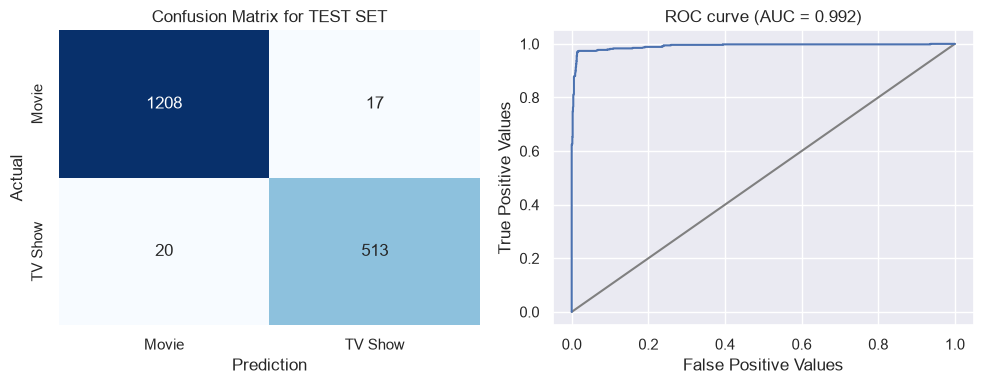

In [805]:
y_pred = best_model.predict(X_test)
proba = best_model.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(1,2, figsize=(10,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0], xticklabels=["Movie", "TV Show"], yticklabels=["Movie", "TV Show"])
ax[0].set_xlabel("Prediction")
ax[0].set_ylabel("Actual")
ax[0].set_title("Confusion Matrix for TEST SET")

fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot([0, 1], [0, 1], color="grey")
ax[1].plot(fpr, tpr)
ax[1].set_xlabel("False Positive Values")
ax[1].set_ylabel("True Positive Values")
ax[1].set_title(f"ROC curve (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.tight_layout()
plt.show()

### **8. Building a Predictive System**

In [806]:
import pandas as pd

def predict_Movie_TVShow(input_features):

    # create Dataframe with correct column order
    input_df = pd.DataFrame(
        [input_features],
        columns=X_train.columns
    )

    # class prediction
    prediction = best_model.predict(input_df)[0]

    # probability prediction (positive class)
    probability = best_model.predict_proba(input_df)[0][1]

    # output
    print(f"Predicted class: {prediction}    (0 => Movie,   1 => TV Show)")
    print(f"Type prediction: {probability:.2%}")

    if prediction == 1:
        print("Predicted TV Show 📺")
    else:
        print("Predicted Movie 🎥")  

    return prediction, probability

In [807]:
y_test[y_test == 1].head()

7364    1
2587    1
8233    1
8236    1
7083    1
Name: type, dtype: int64

In [808]:
# sample datapoint to test the model 
test_1 = X_test.loc[7364].tolist()
print(test_1)

[2014, 2020, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [809]:
predict_Movie_TVShow(test_1)

Predicted class: 1    (0 => Movie,   1 => TV Show)
Type prediction: 99.01%
Predicted TV Show 📺


(np.int64(1), np.float64(0.9900721943835776))

In [810]:
y_test[y_test == 0].head()

5767    0
4674    0
6124    0
6176    0
4742    0
Name: type, dtype: int64

In [811]:
test_2 = X_test.loc[5767].tolist()
print(test_2)

[1990, 2019, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0]


In [812]:
predict_Movie_TVShow(test_2)

Predicted class: 0    (0 => Movie,   1 => TV Show)
Type prediction: 0.14%
Predicted Movie 🎥


(np.int64(0), np.float64(0.0014151263771852384))